In [53]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

In [54]:
data=pd.read_csv('data_ecommerce_customer_churn.csv')
data

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0
...,...,...,...,...,...,...,...,...,...,...,...
3936,28.0,9.0,5,Fashion,3,Married,8,0,1.0,231.86,0
3937,8.0,7.0,2,Mobile Phone,2,Single,4,0,4.0,157.80,0
3938,30.0,6.0,5,Laptop & Accessory,3,Married,3,1,2.0,156.60,0
3939,6.0,NaN,4,Mobile,3,Married,10,1,0.0,124.37,1


In [55]:
data.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [56]:
data.tail()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
3936,28.0,9.0,5,Fashion,3,Married,8,0,1.0,231.86,0
3937,8.0,7.0,2,Mobile Phone,2,Single,4,0,4.0,157.80,0
3938,30.0,6.0,5,Laptop & Accessory,3,Married,3,1,2.0,156.60,0
3939,6.0,NaN,4,Mobile,3,Married,10,1,0.0,124.37,1
3940,2.0,7.0,3,Laptop & Accessory,5,Married,1,0,2.0,153.73,0


In [57]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


In [58]:
data.isna().sum()

Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

In [59]:
data['Tenure'] = data['Tenure'].fillna(data['Tenure'].median())

In [60]:
data['WarehouseToHome'] = data['WarehouseToHome'].fillna(data['Tenure'].median())

In [61]:
data['DaySinceLastOrder'] = data['DaySinceLastOrder'].fillna(data['Tenure'].median())

In [62]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3941 non-null   float64
 1   WarehouseToHome           3941 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3941 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


In [63]:
data.isna().sum()

Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
dtype: int64

In [64]:
churn_rate = data['Churn'].mean() * 100
print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 17.10%


In [65]:
active = data[data['Churn'] == 0]['SatisfactionScore']
churned = data[data['Churn'] == 1]['SatisfactionScore']

In [66]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(active, churned)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -6.788778593723787
P-value: 1.3001960483704277e-11


In [67]:
if p_value < 0.05:
    print("Reject H₀")
    print("Satisfaction significantly affects churn.")
else:
    print("Fail to reject H₀")
    print("No significant evidence that satisfaction affects churn.")

Reject H₀
Satisfaction significantly affects churn.


In [68]:
Act=print("Average Satisfaction (Active):", active.mean())
Chu=print("Average Satisfaction (Churned):", churned.mean())

Average Satisfaction (Active): 3.0208142026323843
Average Satisfaction (Churned): 3.4154302670623147


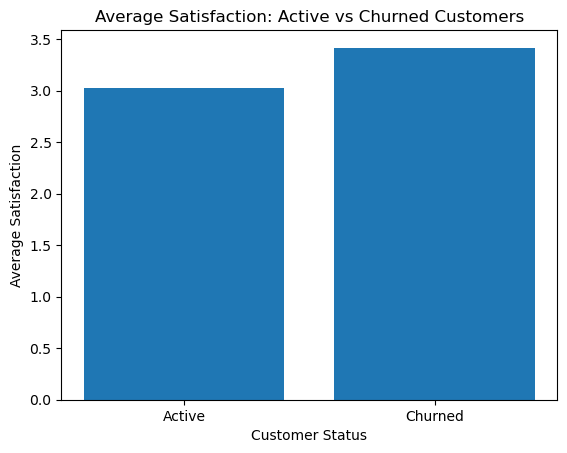

In [69]:
import matplotlib.pyplot as plt

categories = ['Active', 'Churned']
averages = [active.mean(), churned.mean()]

plt.bar(categories, averages)

plt.xlabel('Customer Status')
plt.ylabel('Average Satisfaction')
plt.title('Average Satisfaction: Active vs Churned Customers')

plt.show()

In [70]:
X = data.drop('Churn', axis=1)
y = data['Churn']

In [71]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [72]:
print(data.dtypes)

Tenure                      float64
WarehouseToHome             float64
NumberOfDeviceRegistered      int64
PreferedOrderCat             object
SatisfactionScore             int64
MaritalStatus                object
NumberOfAddress               int64
Complain                      int64
DaySinceLastOrder           float64
CashbackAmount              float64
Churn                         int64
dtype: object


In [73]:
print(data.select_dtypes(include=['object']).columns)

Index(['PreferedOrderCat', 'MaritalStatus'], dtype='object')


In [74]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

data['PreferedOrderCat'] = le.fit_transform(data['PreferedOrderCat'])
data['MaritalStatus'] = le.fit_transform(data['MaritalStatus'])

In [75]:
print(data.select_dtypes(include=['object']).columns)

Index([], dtype='object')


In [76]:
print(data.dtypes)

Tenure                      float64
WarehouseToHome             float64
NumberOfDeviceRegistered      int64
PreferedOrderCat              int64
SatisfactionScore             int64
MaritalStatus                 int64
NumberOfAddress               int64
Complain                      int64
DaySinceLastOrder           float64
CashbackAmount              float64
Churn                         int64
dtype: object


In [77]:
data

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,2,3,2,2,0,7.0,143.32,0
1,7.0,25.0,4,3,1,1,2,0,7.0,129.29,0
2,27.0,13.0,3,2,1,1,5,0,7.0,168.54,0
3,20.0,25.0,4,0,3,0,7,0,9.0,230.27,0
4,30.0,15.0,4,5,4,2,8,0,8.0,322.17,0
...,...,...,...,...,...,...,...,...,...,...,...
3936,28.0,9.0,5,0,3,1,8,0,1.0,231.86,0
3937,8.0,7.0,2,4,2,2,4,0,4.0,157.80,0
3938,30.0,6.0,5,2,3,1,3,1,2.0,156.60,0
3939,6.0,9.0,4,3,3,1,10,1,0.0,124.37,1


In [78]:
X = data.drop('Churn', axis=1)
y = data['Churn']

In [79]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

ValueError: could not convert string to float: 'Fashion'

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
print(X_train.dtypes)

In [ ]:
print(X_train.select_dtypes(include=['object']).columns)

In [80]:
import statsmodels.api as sm

X = data[['SatisfactionScore']]
X = sm.add_constant(X)
y = data['Churn']

model = sm.Logit(y, X)
result = model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.451619
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 3941
Model:                          Logit   Df Residuals:                     3939
Method:                           MLE   Df Model:                            1
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                 0.01286
Time:                        00:38:05   Log-Likelihood:                -1779.8
converged:                       True   LL-Null:                       -1803.0
Covariance Type:            nonrobust   LLR p-value:                 9.700e-12
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -2.2646      0.115    -19.741      0.000      -2.489      -2.040
Satisfac

In [81]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [82]:
model.fit(X_train, y_train)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [83]:
print(y_train.dtypes)

int64


In [84]:
print(type(X_train))
print(type(y_train))

print(X_train.shape)
print(y_train.shape)

print(X_train.dtypes)
print(y_train.dtype)

print(y_train.head())

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>
(3152, 2)
(3152,)
const                float64
SatisfactionScore      int64
dtype: object
int64
3752    0
1188    0
3364    1
1926    0
3578    0
Name: Churn, dtype: int64


In [85]:
print(y_train.info)

<bound method Series.info of 3752    0
1188    0
3364    1
1926    0
3578    0
       ..
1130    0
1294    1
860     1
3507    0
3174    0
Name: Churn, Length: 3152, dtype: int64>


In [86]:
result = model.fit()

Optimization terminated successfully.
         Current function value: 0.451619
         Iterations 6


In [87]:
data.corr()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
Tenure,1.000000,-0.007544,-0.022265,-0.177937,-0.042268,-0.090178,0.221866,-0.017975,0.177755,0.453206,-0.345922
WarehouseToHome,-0.007544,1.000000,0.041047,-0.095840,0.006201,-0.022468,0.004967,0.028483,0.038172,0.036946,0.053072
NumberOfDeviceRegistered,-0.022265,0.041047,1.000000,0.040825,-0.005504,0.039602,0.077813,0.013885,0.035059,0.128373,0.108464
PreferedOrderCat,-0.177937,-0.095840,0.040825,1.000000,0.010694,0.045771,-0.082490,-0.004806,-0.268099,-0.273996,0.124886
SatisfactionScore,-0.042268,0.006201,-0.005504,0.010694,1.000000,-0.037713,0.047638,-0.033975,0.019269,-0.006496,0.107541
MaritalStatus,-0.090178,-0.022468,0.039602,0.045771,-0.037713,1.000000,-0.008340,-0.000248,-0.046798,-0.077380,0.142085
NumberOfAddress,0.221866,0.004967,0.077813,-0.082490,0.047638,-0.008340,1.000000,-0.005070,-0.038532,0.182821,0.039195
Complain,-0.017975,0.028483,0.013885,-0.004806,-0.033975,-0.000248,-0.005070,1.000000,-0.047519,0.010934,0.261450
DaySinceLastOrder,0.177755,0.038172,0.035059,-0.268099,0.019269,-0.046798,-0.038532,-0.047519,1.000000,0.380120,-0.146906
CashbackAmount,0.453206,0.036946,0.128373,-0.273996,-0.006496,-0.077380,0.182821,0.010934,0.380120,1.000000,-0.161535


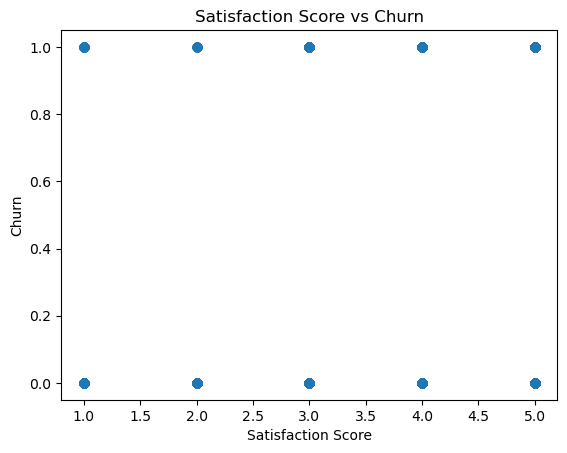

In [88]:
import matplotlib.pyplot as plt

plt.scatter(data['SatisfactionScore'], data['Churn'])
plt.xlabel('Satisfaction Score')
plt.ylabel('Churn')
plt.title('Satisfaction Score vs Churn')
plt.show()

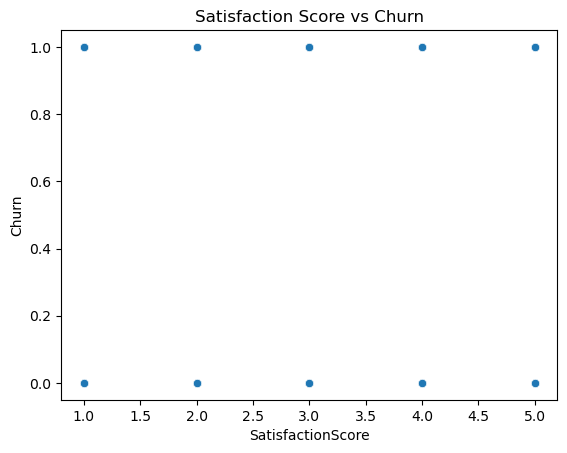

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data, x='SatisfactionScore', y='Churn')
plt.title('Satisfaction Score vs Churn')
plt.show()

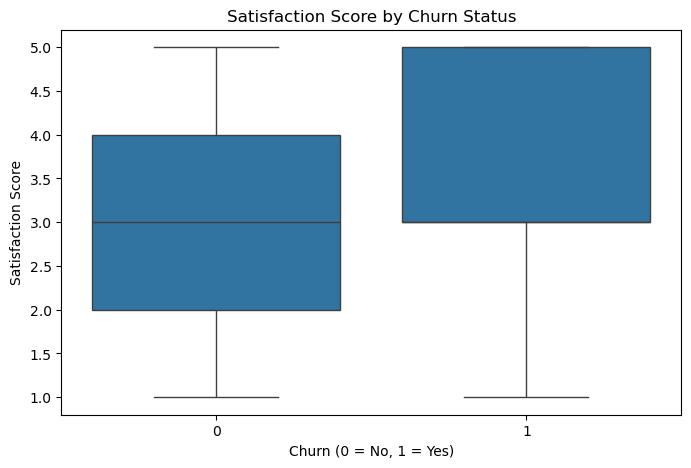

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.boxplot(x='Churn', y='SatisfactionScore',data=data)

plt.title('Satisfaction Score by Churn Status')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Satisfaction Score')

plt.show()

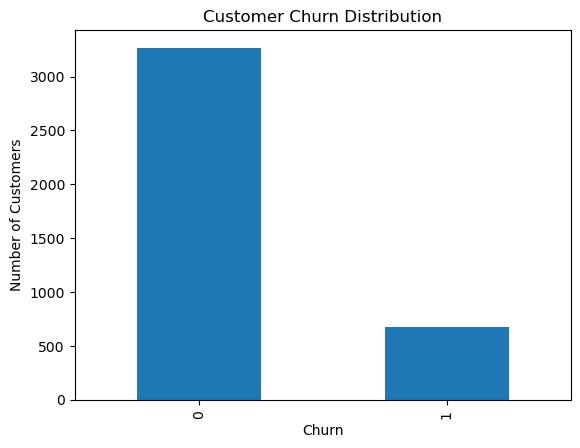

In [91]:
import matplotlib.pyplot as plt

data['Churn'].value_counts().plot(kind='bar')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

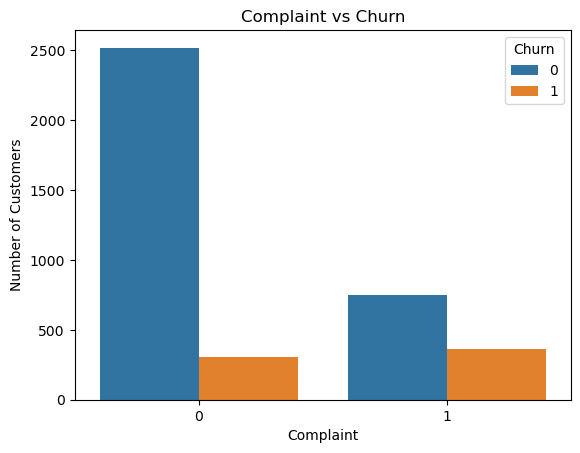

In [92]:

sns.countplot(data=data, x='Complain', hue='Churn')

plt.title('Complaint vs Churn')
plt.xlabel('Complaint')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')
plt.show()

In [93]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
!pip install xgboost
import xgboost
%pip install lightgbm
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42),
    "LightGBM": LGBMClassifier(random_state=42)
}

results = []
X = data.drop('Churn', axis=1)
y = data['Churn']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

for name, model in models.items():
    
    # Train
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Results Table
results_df = pd.DataFrame(results)

# Sort by ROC-AUC
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)

print(results_df)

Note: you may need to restart the kernel to use updated packages.
[LightGBM] [Info] Number of positive: 545, number of negative: 2607
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000549 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 379
[LightGBM] [Info] Number of data points in the train set: 3152, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.172906 -> initscore=-1.565170
[LightGBM] [Info] Start training from score -1.565170
                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
2        Random Forest  0.949303   0.844961  0.844961  0.844961  0.979123
3              XGBoost  0.939163   0.809160  0.821705  0.815385  0.973843
4             LightGBM  0.935361   0.814516  0.782946  0.798419  0.970707
1        Decision Tree  0.925222   0.761194  0.790698  0.775665  0.871106
0  Logistic Regression  0.880862   0.746479  0.410853  0.530000  0.857376


[LightGBM] [Info] Number of positive: 545, number of negative: 2607
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000087 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 379
[LightGBM] [Info] Number of data points in the train set: 3152, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.172906 -> initscore=-1.565170
[LightGBM] [Info] Start training from score -1.565170


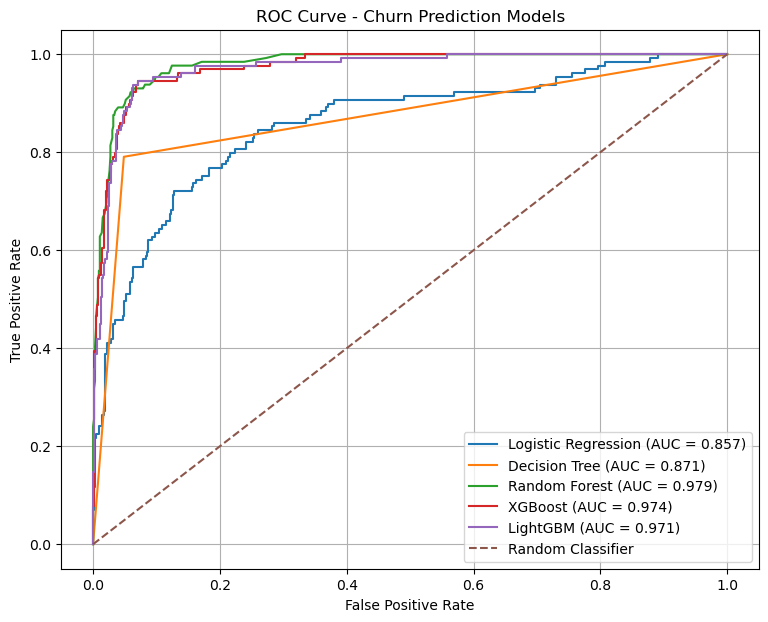

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42),
    "LightGBM": LGBMClassifier(random_state=42)
}

plt.figure(figsize=(9, 7))

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Probability of Churn = 1
    y_prob = model.predict_proba(X_test)[:, 1]

    # ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # AUC
    auc = roc_auc_score(y_test, y_prob)

    # Plot
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Random classifier
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Churn Prediction Models')
plt.legend()
plt.grid()
plt.show()

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_pred = model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Churn', 'Churn']
)

disp.plot()
plt.title('Confusion Matrix - Customer Churn Prediction')
plt.show()

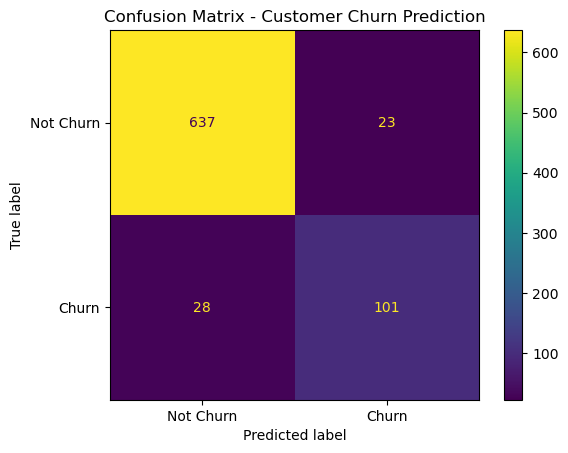

In [95]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions
y_pred = model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Churn', 'Churn']
)

disp.plot()
plt.title('Confusion Matrix - Customer Churn Prediction')
plt.show()

In [96]:
%pip install shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


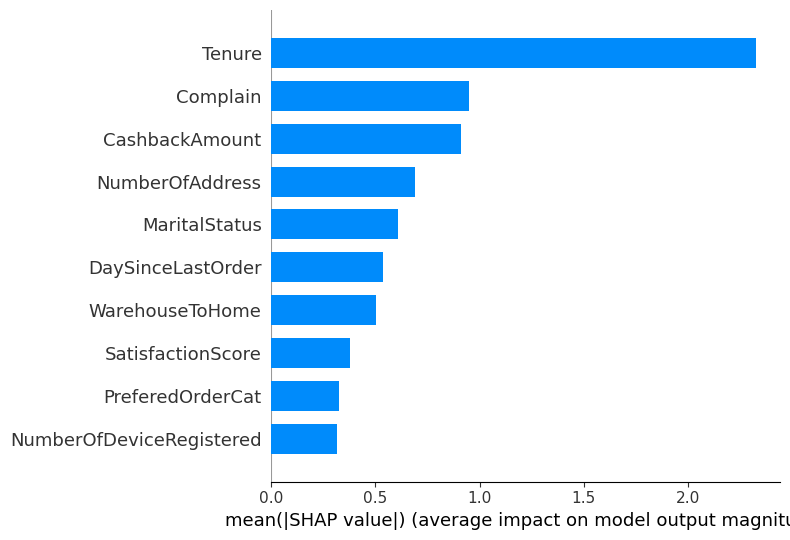

In [97]:
import shap
import matplotlib.pyplot as plt

# Train your XGBoost model
model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train, y_train)

# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

# Summary bar plot
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

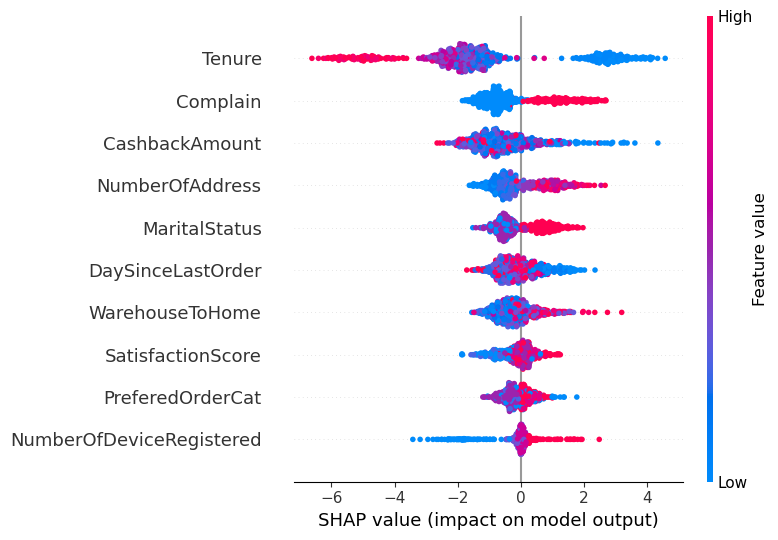

In [98]:
import shap
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test
)

In [100]:
%pip install lime.lime_tabular

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement lime.lime_tabular (from versions: none)
ERROR: No matching distribution found for lime.lime_tabular


In [101]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np

explainer = LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['Not Churn', 'Churn'],
    mode='classification',
    random_state=42
)

ModuleNotFoundError: No module named 'lime'